# JobGuard AI - Milestone 6: XGBoost

**Goal:** train XGBoost, our first *advanced* model, using the same validation-based protocol as Milestone 5.

| Data | Used for |
|---|---|
| **Model-training subset** (80% of `train.csv`) | teaching each model |
| **Validation subset** (20% of `train.csv`) | **choosing between model settings and comparing models** |
| **Test set** (`test.csv`) | **untouched**, saved for the final comparison of all models |

**Plan**
1. Recreate the exact same internal split as Milestone 5
2. Turn text into TF-IDF features (kept sparse)
3. Train a baseline XGBoost and a class-weighted XGBoost, plus one moderate-weight option
4. Pick the best XGBoost setting **on validation data**
5. Compare it with balanced Logistic Regression and Naive Bayes on the same validation set
6. Retrain the selected XGBoost on the full `train.csv` and save it

**No test-set metrics are calculated anywhere in this notebook.** DistilBERT comes in the next milestone.

## 1. Dependencies and paths

Libraries: pandas, numpy, matplotlib, scikit-learn, xgboost and joblib. (`xgboost` was added to `requirements.txt`; on a Mac it also needs the OpenMP library: `brew install libomp`.)

As in Milestone 5, we record a **fingerprint** (MD5 hash) of `train.csv` and `test.csv` now and check it again at the end, to prove neither file was changed.

In [1]:
import hashlib
import subprocess
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

sys.path.append("..")   # project root, so "from src..." works
from src.evaluation import calculate_metrics, plot_confusion_matrix
from src.preprocessing import create_combined_text

PROCESSED_DIR = Path("../data/processed")
FIGURES_DIR = Path("../results/figures")
METRICS_DIR = Path("../results/metrics")
MODELS_DIR = Path("../models")
for folder in [FIGURES_DIR, METRICS_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Same TF-IDF settings as the traditional models
tfidf_settings = dict(lowercase=True, stop_words="english",
                      ngram_range=(1, 2), min_df=2, max_features=20000)


def file_fingerprint(path):
    return hashlib.md5(Path(path).read_bytes()).hexdigest()


fingerprints_at_start = {
    "train.csv": file_fingerprint(PROCESSED_DIR / "train.csv"),
    "test.csv": file_fingerprint(PROCESSED_DIR / "test.csv"),
}
print("xgboost-ready environment OK; fingerprints recorded for train.csv and test.csv")

xgboost-ready environment OK; fingerprints recorded for train.csv and test.csv


## 2. Load the training data

We load `train.csv`. For `test.csv` we only read **how many rows it has**. Its text and labels are not stored in any variable and no predictions or metrics are made from it.

In [2]:
train = pd.read_csv(PROCESSED_DIR / "train.csv")
X = train["combined_text"]
y = train["fraudulent"]

test_rows = len(pd.read_csv(PROCESSED_DIR / "test.csv", usecols=["fraudulent"]))   # size only

print("train.csv shape:", train.shape)
print("test.csv rows (size only, reserved for the final comparison):", test_rows)

train.csv shape: (12852, 5)
test.csv rows (size only, reserved for the final comparison): 3214


## 3. Recreate the internal split

Exactly the same call as in Milestone 5 (`test_size=0.20`, `random_state=42`, `stratify=y`), so every model is judged on the **same** validation postings.

In [3]:
(X_model_train, X_validation,
 y_model_train, y_validation) = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print(f"Model-training rows: {len(X_model_train):,}   fraudulent: {int(y_model_train.sum())} "
      f"({y_model_train.mean() * 100:.2f}%)")
print(f"Validation rows:     {len(X_validation):,}   fraudulent: {int(y_validation.sum())} "
      f"({y_validation.mean() * 100:.2f}%)")

shared_texts = set(X_model_train) & set(X_validation)
print("Identical combined_text values in both subsets:", len(shared_texts))
assert len(shared_texts) == 0

Model-training rows: 10,281   fraudulent: 459 (4.46%)
Validation rows:     2,571   fraudulent: 115 (4.47%)
Identical combined_text values in both subsets: 0


We will confirm further down that this split matches Milestone 5, by checking that the saved Milestone 5 results can be reproduced from it.

## 4. What is XGBoost?

**XGBoost** stands for **E**xtreme **G**radient **Boost**ing. It is built from **decision trees**, which are simple flowcharts of yes/no questions (for example, "does this posting contain the phrase *data entry*?").

**The boosting idea:**
1. Build a small, simple tree. On its own it is not very accurate.
2. Build a **second tree that focuses on the mistakes** the first tree made.
3. Build a third tree that focuses on the mistakes that are still left, and so on, for hundreds of trees.
4. To predict, **add up the votes** of all the trees.

Each tree is small and "weak", but together they form a strong model. Because the trees ask different kinds of questions and can combine them, XGBoost can learn **nonlinear patterns** (for example, "this word matters only when that other word is also present"). Logistic Regression can only add up each word's effect separately.

**Why is it more advanced than a single Decision Tree?** One tree is easy to read but tends to memorize its training data and generalize poorly. Boosting builds many small trees that correct each other, and XGBoost adds extras such as randomly sampling rows and features for each tree (`subsample`, `colsample_bytree`) to reduce overfitting.

**Why can it work with TF-IDF?** A tree can ask a question like "is the TF-IDF value of this word greater than 0.05?", so TF-IDF columns are perfectly good inputs. TF-IDF matrices are also mostly zeros, and XGBoost handles **sparse** data efficiently.

## 5. TF-IDF features (kept sparse)

We use the same TF-IDF as the traditional models, fitted **only on the model-training subset**. The validation text is only **transformed**.

**Important: we keep the matrices sparse.** Each posting uses only a few hundred of the 20,000 columns, so almost every cell is 0. A sparse matrix stores just the non-zero values. Converting to a dense array would store all of the zeros too, which would waste a large amount of memory for no benefit.

In [4]:
tfidf = TfidfVectorizer(**tfidf_settings)

X_model_train_tfidf = tfidf.fit_transform(X_model_train)   # learn vocabulary from the training subset only
X_validation_tfidf = tfidf.transform(X_validation)         # transform only

print("Vocabulary size:                   ", len(tfidf.get_feature_names_out()))
print("Model-training TF-IDF matrix shape:", X_model_train_tfidf.shape)
print("Validation TF-IDF matrix shape:    ", X_validation_tfidf.shape)
print("Matrices are sparse:", sparse.issparse(X_model_train_tfidf) and sparse.issparse(X_validation_tfidf))

# How much memory sparse storage saves versus a dense array of the same shape
non_zero_cells = X_model_train_tfidf.nnz
total_cells = X_model_train_tfidf.shape[0] * X_model_train_tfidf.shape[1]
sparse_mb = (X_model_train_tfidf.data.nbytes + X_model_train_tfidf.indices.nbytes + X_model_train_tfidf.indptr.nbytes) / 1e6
dense_mb = total_cells * 8 / 1e6
print(f"Non-zero cells: {non_zero_cells:,} of {total_cells:,} ({non_zero_cells / total_cells * 100:.2f}%)")
print(f"Memory: sparse ~{sparse_mb:,.0f} MB vs dense ~{dense_mb:,.0f} MB")

Vocabulary size:                    20000
Model-training TF-IDF matrix shape: (10281, 20000)
Validation TF-IDF matrix shape:     (2571, 20000)
Matrices are sparse: True
Non-zero cells: 2,422,668 of 205,620,000 (1.18%)
Memory: sparse ~29 MB vs dense ~1,645 MB


## 6. Measuring the class imbalance

Fraudulent postings are rare. XGBoost has a setting called **`scale_pos_weight`** that tells it how much more to care about mistakes on the positive (fraud) class. A common starting value is:

> `scale_pos_weight = (number of legitimate postings) / (number of fraudulent postings)`

With this value, one fraudulent posting counts about as much as that many legitimate ones. It makes the model pay more attention to fraud, but it **does not automatically make the model better**: it usually increases recall while lowering precision. We calculate it from the training labels instead of typing it in.

In [5]:
negative_count = int((y_model_train == 0).sum())   # legitimate
positive_count = int((y_model_train == 1).sum())   # fraudulent

scale_pos_weight = negative_count / positive_count

print("Legitimate postings (model-training subset):", f"{negative_count:,}")
print("Fraudulent postings (model-training subset):", f"{positive_count:,}")
print("scale_pos_weight = legitimate / fraudulent =", round(scale_pos_weight, 3))

Legitimate postings (model-training subset): 9,822
Fraudulent postings (model-training subset): 459
scale_pos_weight = legitimate / fraudulent = 21.399


## 7. Baseline XGBoost (`scale_pos_weight=1`)

Fixed, sensible settings (no big search):

| Setting | Meaning |
|---|---|
| `n_estimators=200` | build 200 trees |
| `max_depth=4` | each tree asks at most 4 questions in a row (keeps trees simple) |
| `learning_rate=0.05` | each new tree makes only a small correction (slow and careful) |
| `subsample=0.8`, `colsample_bytree=0.8` | each tree sees 80% of the rows and 80% of the features |
| `random_state=42` | repeatable results |

The baseline gives fraud mistakes no extra weight (`scale_pos_weight=1`). We train on the **model-training subset** and evaluate on the **validation subset** only.

In [6]:
xgb_params = dict(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
)

xgb_baseline = XGBClassifier(**xgb_params, scale_pos_weight=1)
xgb_baseline.fit(X_model_train_tfidf, y_model_train)

baseline_pred = xgb_baseline.predict(X_validation_tfidf)
baseline_metrics = calculate_metrics(y_validation, baseline_pred)

print("XGBoost baseline (VALIDATION results)")
print(f"  Accuracy:        {baseline_metrics['Accuracy']:.4f}")
print(f"  Fraud precision: {baseline_metrics['Fraud Precision']:.4f}")
print(f"  Fraud recall:    {baseline_metrics['Fraud Recall']:.4f}")
print(f"  Fraud F1-score:  {baseline_metrics['Fraud F1']:.4f}")
print()
print(f"  True Negatives: {baseline_metrics['True Negatives']}   False Positives: {baseline_metrics['False Positives']}")
print(f"  False Negatives: {baseline_metrics['False Negatives']}   True Positives: {baseline_metrics['True Positives']}")

XGBoost baseline (VALIDATION results)
  Accuracy:        0.9759
  Fraud precision: 0.9344
  Fraud recall:    0.4957
  Fraud F1-score:  0.6477

  True Negatives: 2452   False Positives: 4
  False Negatives: 58   True Positives: 57


In [7]:
print(classification_report(y_validation, baseline_pred,
                            target_names=["Legitimate (0)", "Fraudulent (1)"], digits=3, zero_division=0))

                precision    recall  f1-score   support

Legitimate (0)      0.977     0.998     0.988      2456
Fraudulent (1)      0.934     0.496     0.648       115

      accuracy                          0.976      2571
     macro avg      0.956     0.747     0.818      2571
  weighted avg      0.975     0.976     0.972      2571



## 8. Imbalance-weighted XGBoost

Same settings and features, but now `scale_pos_weight` equals the ratio we calculated. Mistakes on fraudulent postings are punished far more during training.

In [8]:
xgb_weighted = XGBClassifier(**xgb_params, scale_pos_weight=scale_pos_weight)
xgb_weighted.fit(X_model_train_tfidf, y_model_train)

weighted_pred = xgb_weighted.predict(X_validation_tfidf)
weighted_metrics = calculate_metrics(y_validation, weighted_pred)

print(f"XGBoost weighted, scale_pos_weight={scale_pos_weight:.2f} (VALIDATION results)")
print(f"  Accuracy:        {weighted_metrics['Accuracy']:.4f}")
print(f"  Fraud precision: {weighted_metrics['Fraud Precision']:.4f}")
print(f"  Fraud recall:    {weighted_metrics['Fraud Recall']:.4f}")
print(f"  Fraud F1-score:  {weighted_metrics['Fraud F1']:.4f}")
print()
print(f"  True Negatives: {weighted_metrics['True Negatives']}   False Positives: {weighted_metrics['False Positives']}")
print(f"  False Negatives: {weighted_metrics['False Negatives']}   True Positives: {weighted_metrics['True Positives']}")

XGBoost weighted, scale_pos_weight=21.40 (VALIDATION results)
  Accuracy:        0.9378
  Fraud precision: 0.4051
  Fraud recall:    0.8348
  Fraud F1-score:  0.5455

  True Negatives: 2315   False Positives: 141
  False Negatives: 19   True Positives: 96


In [9]:
print(classification_report(y_validation, weighted_pred,
                            target_names=["Legitimate (0)", "Fraudulent (1)"], digits=3, zero_division=0))

                precision    recall  f1-score   support

Legitimate (0)      0.992     0.943     0.967      2456
Fraudulent (1)      0.405     0.835     0.545       115

      accuracy                          0.938      2571
     macro avg      0.698     0.889     0.756      2571
  weighted avg      0.966     0.938     0.948      2571



In [10]:
# What changed when we added the weight?
for metric in ["Fraud Precision", "Fraud Recall", "Fraud F1"]:
    print(f"{metric:16s} weighted - baseline = {weighted_metrics[metric] - baseline_metrics[metric]:+.4f}")
print("Missed scams (false negatives):", baseline_metrics["False Negatives"], "->", weighted_metrics["False Negatives"])
print("False alarms (false positives):", baseline_metrics["False Positives"], "->", weighted_metrics["False Positives"])

Fraud Precision  weighted - baseline = -0.5294
Fraud Recall     weighted - baseline = +0.3391
Fraud F1         weighted - baseline = -0.1023
Missed scams (false negatives): 58 -> 19
False alarms (false positives): 4 -> 141


**What changed:** with the full imbalance weight, XGBoost became much more aggressive about calling postings fraudulent. It **misses far fewer scams** (higher recall), but its **precision dropped sharply** and it raised **many more false alarms**, so its fraud F1 ended up *lower* than the baseline. This shows that class weighting is **not automatically better**: it moves errors from one type to the other, and too much weight moves too many.

## 9. One moderate-weight option

The fully weighted model swings far toward recall at the cost of many more false alarms (compare the false positives above). This is the kind of extreme trade-off where a **gentler** weight may help, so we test **exactly one** intermediate setting:

> `scale_pos_weight = sqrt(legitimate / fraudulent)`

(The square root is much smaller than the full ratio but still above 1.) This is labeled **XGBoost (Moderate Weight)**. We do not try any other weights.

In [11]:
moderate_weight = float(np.sqrt(negative_count / positive_count))

xgb_moderate = XGBClassifier(**xgb_params, scale_pos_weight=moderate_weight)
xgb_moderate.fit(X_model_train_tfidf, y_model_train)

moderate_pred = xgb_moderate.predict(X_validation_tfidf)
moderate_metrics = calculate_metrics(y_validation, moderate_pred)

print(f"XGBoost (Moderate Weight), scale_pos_weight={moderate_weight:.2f} (VALIDATION results)")
print(f"  Accuracy:        {moderate_metrics['Accuracy']:.4f}")
print(f"  Fraud precision: {moderate_metrics['Fraud Precision']:.4f}")
print(f"  Fraud recall:    {moderate_metrics['Fraud Recall']:.4f}")
print(f"  Fraud F1-score:  {moderate_metrics['Fraud F1']:.4f}")
print()
print(f"  True Negatives: {moderate_metrics['True Negatives']}   False Positives: {moderate_metrics['False Positives']}")
print(f"  False Negatives: {moderate_metrics['False Negatives']}   True Positives: {moderate_metrics['True Positives']}")

XGBoost (Moderate Weight), scale_pos_weight=4.63 (VALIDATION results)
  Accuracy:        0.9798
  Fraud precision: 0.8462
  Fraud recall:    0.6696
  Fraud F1-score:  0.7476

  True Negatives: 2442   False Positives: 14
  False Negatives: 38   True Positives: 77


## 10. Choose the XGBoost configuration

All three XGBoost configurations on the **validation** set:

In [12]:
xgb_results = pd.DataFrame([
    {"Model": "XGBoost (Baseline)", "scale_pos_weight": 1.0, **baseline_metrics},
    {"Model": "XGBoost (Weighted)", "scale_pos_weight": scale_pos_weight, **weighted_metrics},
    {"Model": "XGBoost (Moderate Weight)", "scale_pos_weight": moderate_weight, **moderate_metrics},
])

comparison_columns = ["Model", "Accuracy", "Fraud Precision", "Fraud Recall", "Fraud F1"]
xgb_results[comparison_columns + ["scale_pos_weight"]].round(4)

,Model,Accuracy,Fraud Precision,Fraud Recall,Fraud F1,scale_pos_weight
0,XGBoost (Baseline),0.9759,0.9344,0.4957,0.6477,1.0000
1,XGBoost (Weighted),0.9378,0.4051,0.8348,0.5455,21.3987
2,XGBoost (Moderate Weight),0.9798,0.8462,0.6696,0.7476,4.6259


In [13]:
best_xgb = xgb_results.loc[xgb_results["Fraud F1"].idxmax()]
selected_xgb_name = best_xgb["Model"]
selected_weight_rule = {"XGBoost (Baseline)": "baseline",
                        "XGBoost (Weighted)": "weighted",
                        "XGBoost (Moderate Weight)": "moderate"}[selected_xgb_name]

print("Selected XGBoost configuration:", selected_xgb_name)
print(f"  scale_pos_weight {best_xgb['scale_pos_weight']:.3f} | validation fraud F1 {best_xgb['Fraud F1']:.4f} "
      f"| precision {best_xgb['Fraud Precision']:.4f} | recall {best_xgb['Fraud Recall']:.4f}")
print(f"  Missed scams (FN): {int(best_xgb['False Negatives'])} | False alarms (FP): {int(best_xgb['False Positives'])}")

Selected XGBoost configuration: XGBoost (Moderate Weight)
  scale_pos_weight 4.626 | validation fraud F1 0.7476 | precision 0.8462 | recall 0.6696
  Missed scams (FN): 38 | False alarms (FP): 14


### Reading the three XGBoost results

- **Baseline** (no weight): very high precision, but it **misses about half of the scams** (low recall).
- **Fully weighted:** catches most scams, but at the cost of many false alarms, which lowers precision a lot and lowers F1.
- **Moderate weight:** a middle path. Compared with the baseline it catches more scams while keeping false alarms low, and it has the **best fraud F1** of the three, so it is the one we select.

**The trade-off in JobGuard terms.** A **false negative** (a scam called legitimate) can cost a job seeker money or personal data. A **false positive** (a real job flagged) damages trust in JobGuard and unfairly flags honest employers. The selected setting leans toward few false alarms while catching a moderate share of scams. If we decided that missing scams is much worse than false alarms, a heavier weight would be more attractive, but then we would need to accept many more false warnings.

**Caveats.** We tried one setting per idea, not a full search. The moderate weight was added after seeing that the full weight was extreme (we looked only at validation results). And with a limited number of fraudulent validation postings, small score differences should not be over-interpreted.

## 11. Confusion matrix: selected XGBoost (validation)

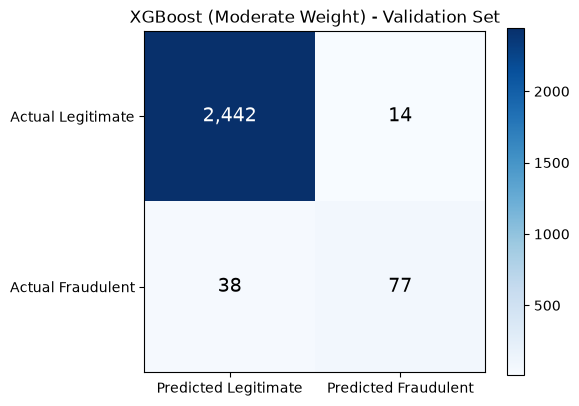

True Negatives : 2442
False Positives: 14
False Negatives: 38
True Positives : 77


In [14]:
selected_models = {"XGBoost (Baseline)": (xgb_baseline, baseline_pred),
                   "XGBoost (Weighted)": (xgb_weighted, weighted_pred),
                   "XGBoost (Moderate Weight)": (xgb_moderate, moderate_pred)}
xgb_selected, xgb_selected_pred = selected_models[selected_xgb_name]
xgb_selected_metrics = calculate_metrics(y_validation, xgb_selected_pred)

plot_confusion_matrix(y_validation, xgb_selected_pred,
                      f"{selected_xgb_name} - Validation Set",
                      FIGURES_DIR / "xgboost_validation_confusion_matrix.png")

print("True Negatives :", xgb_selected_metrics["True Negatives"])
print("False Positives:", xgb_selected_metrics["False Positives"])
print("False Negatives:", xgb_selected_metrics["False Negatives"])
print("True Positives :", xgb_selected_metrics["True Positives"])

## 12. Compare all models so far (validation)

The Logistic Regression and Naive Bayes results are **read from the metrics file saved in Milestone 5**, not retyped. That file was produced on this same validation split. To be sure the split really is identical, we first **recompute** both models here and check that they give the same numbers as the saved file.

In [15]:
saved_traditional = pd.read_csv(METRICS_DIR / "traditional_models_validation_comparison.csv")
saved_traditional[["Model", "Configuration", "Accuracy", "Fraud Precision", "Fraud Recall", "Fraud F1"]].round(4)

,Model,Configuration,Accuracy,Fraud Precision,Fraud Recall,Fraud F1
0,Logistic Regression (Balanced),class_weight=balanced,0.9701,0.6118,0.9043,0.7298
1,Multinomial Naive Bayes,"alpha=0.1, fit_prior=True",0.9798,0.8987,0.6174,0.7320


In [16]:
# Recompute both traditional models on THIS split and compare with the saved file
logistic_check = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
logistic_check.fit(X_model_train_tfidf, y_model_train)
logistic_check_metrics = calculate_metrics(y_validation, logistic_check.predict(X_validation_tfidf))

nb_configuration = saved_traditional.loc[saved_traditional["Model"] == "Multinomial Naive Bayes", "Configuration"].iloc[0]
nb_alpha = float(nb_configuration.split(",")[0].split("=")[1])   # e.g. "alpha=0.1, fit_prior=True" -> 0.1
nb_check = MultinomialNB(alpha=nb_alpha)
nb_check.fit(X_model_train_tfidf, y_model_train)
nb_check_metrics = calculate_metrics(y_validation, nb_check.predict(X_validation_tfidf))

metric_names = ["Accuracy", "Fraud Precision", "Fraud Recall", "Fraud F1"]
saved_lr = saved_traditional[saved_traditional["Model"].str.startswith("Logistic")].iloc[0]
saved_nb = saved_traditional[saved_traditional["Model"].str.startswith("Multinomial")].iloc[0]

assert np.allclose([logistic_check_metrics[m] for m in metric_names], [saved_lr[m] for m in metric_names])
assert np.allclose([nb_check_metrics[m] for m in metric_names], [saved_nb[m] for m in metric_names])
print("PASS: recomputed Logistic Regression and Naive Bayes match the saved Milestone 5 results,")
print("      so this validation split is identical to Milestone 5.")

PASS: recomputed Logistic Regression and Naive Bayes match the saved Milestone 5 results,
      so this validation split is identical to Milestone 5.


In [17]:
xgb_row = {"Model": "XGBoost", "Configuration": f"{selected_xgb_name}, scale_pos_weight={best_xgb['scale_pos_weight']:.2f}",
           **xgb_selected_metrics}

model_comparison = pd.concat([saved_traditional, pd.DataFrame([xgb_row])], ignore_index=True)
model_comparison[["Model", "Accuracy", "Fraud Precision", "Fraud Recall", "Fraud F1",
                  "False Positives", "False Negatives"]].round(4)

,Model,Accuracy,Fraud Precision,Fraud Recall,Fraud F1,False Positives,False Negatives
0,Logistic Regression (Balanced),0.9701,0.6118,0.9043,0.7298,66,11
1,Multinomial Naive Bayes,0.9798,0.8987,0.6174,0.7320,8,44
2,XGBoost,0.9798,0.8462,0.6696,0.7476,14,38


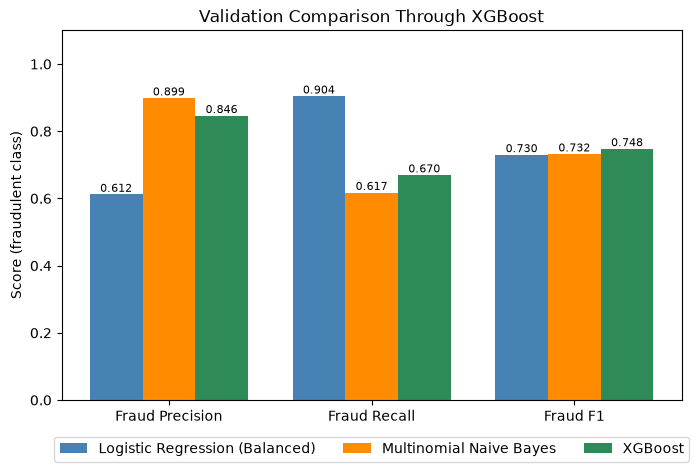

In [18]:
chart_metrics = ["Fraud Precision", "Fraud Recall", "Fraud F1"]
bar_colors = ["steelblue", "darkorange", "seagreen"]
positions = np.arange(len(chart_metrics))
bar_width = 0.26

fig, ax = plt.subplots(figsize=(8, 4.8))
for index, (_, row) in enumerate(model_comparison.iterrows()):
    bars = ax.bar(positions + (index - 1) * bar_width, row[chart_metrics].astype(float),
                  bar_width, label=row["Model"], color=bar_colors[index])
    ax.bar_label(bars, fmt="%.3f", fontsize=8)

ax.set_xticks(positions, labels=chart_metrics)
ax.set_ylim(0, 1.1)
ax.set_ylabel("Score (fraudulent class)")
ax.set_title("Validation Comparison Through XGBoost")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3)
fig.savefig(FIGURES_DIR / "model_comparison_through_xgboost.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
# Plain-language summary printed from the numbers
for _, row in model_comparison.iterrows():
    print(f"{row['Model']:32s} precision {row['Fraud Precision']:.3f} | recall {row['Fraud Recall']:.3f} | "
          f"F1 {row['Fraud F1']:.3f} | missed scams {int(row['False Negatives'])} | false alarms {int(row['False Positives'])}")

Logistic Regression (Balanced)   precision 0.612 | recall 0.904 | F1 0.730 | missed scams 11 | false alarms 66
Multinomial Naive Bayes          precision 0.899 | recall 0.617 | F1 0.732 | missed scams 44 | false alarms 8
XGBoost                          precision 0.846 | recall 0.670 | F1 0.748 | missed scams 38 | false alarms 14


### How the three models compare (validation)

| | Style |
|---|---|
| **Balanced Logistic Regression** | **Catches the most scams** (highest recall) but raises the **most false alarms** (lowest precision) |
| **Multinomial Naive Bayes** | **Fewest false alarms** (highest precision) but **misses more scams** |
| **XGBoost (selected)** | In between: fairly high precision and moderate recall |

XGBoost has the **highest fraud F1**, but the three F1 scores are **close together**, and with so few fraudulent validation postings the differences are small enough that a different random split could change the order. So the safest reading is: *the three models reach similar overall quality but make different kinds of mistakes.* Which one JobGuard prefers depends on how we weigh missed scams against false alarms.

**We do not declare a winner.** DistilBERT has not been trained yet, and the final comparison of all models will use the untouched test set.

## 13. Save the metrics

In [20]:
xgb_results.to_csv(METRICS_DIR / "xgboost_validation_results.csv", index=False)
model_comparison.to_csv(METRICS_DIR / "model_validation_comparison.csv", index=False)
pd.read_csv(METRICS_DIR / "model_validation_comparison.csv")[["Model", "Configuration", "Fraud Precision", "Fraud Recall", "Fraud F1"]].round(4)

,Model,Configuration,Fraud Precision,Fraud Recall,Fraud F1
0,Logistic Regression (Balanced),class_weight=balanced,0.6118,0.9043,0.7298
1,Multinomial Naive Bayes,"alpha=0.1, fit_prior=True",0.8987,0.6174,0.7320
2,XGBoost,"XGBoost (Moderate Weight), scale_pos_weight=4.63",0.8462,0.6696,0.7476


## 14. Which features did XGBoost use?

XGBoost reports a **feature importance** score for every TF-IDF column: roughly, how much that term helped the trees separate fraudulent from legitimate postings. We map each column number back to its word or phrase using the TF-IDF vocabulary.

**Important:**
- Importance only says a term was **useful for separating the classes in this dataset**. It does **not** say the term causes fraud, and it does **not** say whether the term points toward fraud or toward legitimate. (Unlike Logistic Regression, there is no positive or negative sign.)
- To add some context, the table also shows how many model-training postings contain each term and what share of them are fraudulent.

In [21]:
vocabulary = tfidf.get_feature_names_out()
importances = xgb_selected.feature_importances_

top_positions = np.argsort(importances)[::-1][:15]   # 15 largest importances

term_present = X_model_train_tfidf > 0
fraud_rows = (y_model_train.values == 1)

rows = []
for position in top_positions:
    column = term_present[:, position]
    postings_with_term = int(column.sum())
    rows.append({"term": vocabulary[position],
                 "importance": round(float(importances[position]), 4),
                 "training_postings_with_term": postings_with_term,
                 "percent_fraudulent": round(int(column[fraud_rows].sum()) / postings_with_term * 100, 1)})

top_features = pd.DataFrame(rows).set_index("term")
print(f"Non-zero importance features: {int((importances > 0).sum()):,} of {len(vocabulary):,}")
top_features

Non-zero importance features: 600 of 20,000


,importance,training_postings_with_term,percent_fraudulent
term,,,
encouraged,0.0231,201,43.3
28 000,0.0216,48,79.2
profile description,0.0215,1979,15.0
cultural professional,0.0155,26,100.0
facilitating,0.0138,113,13.3
life ad,0.0115,62,33.9
28,0.0114,101,40.6
description,0.0113,10281,4.5
accion,0.0110,12,100.0


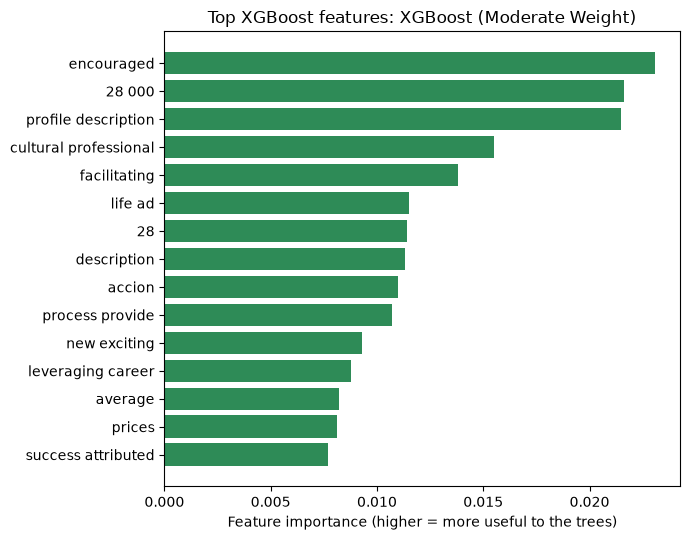

In [22]:
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.barh(top_features.index[::-1], top_features["importance"][::-1], color="seagreen")
ax.set_xlabel("Feature importance (higher = more useful to the trees)")
ax.set_title(f"Top XGBoost features: {selected_xgb_name}")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "xgboost_top_features.png", dpi=150, bbox_inches="tight")
plt.show()

### Reading these features carefully

These are terms XGBoost found **useful for separating the classes in this training data**. They do **not** show that a word causes fraud, and importance has no direction (check the `percent_fraudulent` column for context).

- **Some terms come from the way we built `combined_text`.** `profile description` appears when the company profile is **empty** (our `COMPANY PROFILE:` and `DESCRIPTION:` labels end up side by side), and fraudulent postings are missing the company profile far more often. The word `description` appears in **every** posting because it is one of our section labels. Its TF-IDF value then varies mainly with how long or how structured the posting is, so the trees are probably using it as a **proxy for posting length**, not for meaning.
- **Some terms are rare and almost entirely fraudulent** (for example `accion`, `cultural professional`, `leveraging career`). They appear in only a small number of postings, probably from a few groups of similar ads, so they may not generalize to new scams.
- **Importance is spread thinly.** Only a small fraction of the 20,000 columns were used at all, and no single term dominates.

This is a reminder that the model partly learns **dataset quirks**, which is one reason we keep the test set untouched for an honest final check.

## 15. Retrain the selected XGBoost on the full `train.csv` and save it

The configuration is **decided** (using validation data). For the final saved model we learn from as much training data as possible, so we retrain the chosen setting on **all of `train.csv`**. The test set is not included.

If the chosen configuration uses a class weight, the **same rule** is applied to the full training labels (the ratio changes only slightly with the extra rows). We use one scikit-learn **Pipeline** (TF-IDF + XGBoost) so it accepts raw `combined_text`. Because this pipeline has now seen the validation rows, validation scores would be meaningless, so we do not evaluate it here.

In [23]:
full_negative = int((y == 0).sum())
full_positive = int((y == 1).sum())
full_ratio = full_negative / full_positive

final_weight = {"baseline": 1.0,
                "weighted": full_ratio,
                "moderate": float(np.sqrt(full_ratio))}[selected_weight_rule]
print(f"Weight rule: {selected_weight_rule} -> scale_pos_weight on the full train.csv = {final_weight:.3f} "
      f"(was {best_xgb['scale_pos_weight']:.3f} on the model-training subset)")

xgb_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(**tfidf_settings)),
    ("xgboost", XGBClassifier(**xgb_params, scale_pos_weight=final_weight)),
])
xgb_pipeline.fit(X, y)   # all of train.csv, no test data

PIPELINE_PATH = MODELS_DIR / "xgboost_pipeline.joblib"
joblib.dump(xgb_pipeline, PIPELINE_PATH)
print("Saved:", PIPELINE_PATH, f"({PIPELINE_PATH.stat().st_size / 1_000_000:.1f} MB)  trained on {len(X):,} rows")

Weight rule: moderate -> scale_pos_weight on the full train.csv = 4.625 (was 4.626 on the model-training subset)


Saved: ../models/xgboost_pipeline.joblib (1.1 MB)  trained on 12,852 rows


**Reload in a fresh process.** To be sure the saved file works on its own (not just because everything is still in this notebook's memory), we start a **brand-new Python process**, load the file, and predict from raw text.

In [24]:
fresh_process_script = '''
import joblib, sys
pipeline = joblib.load(sys.argv[1])
text = "TITLE: Barista\\nCOMPANY PROFILE: A friendly local cafe.\\nDESCRIPTION: Make coffee and serve customers.\\nREQUIREMENTS: \\nBENEFITS: "
print("loaded steps:", [name for name, _ in pipeline.steps])
print("predicted class:", int(pipeline.predict([text])[0]))
print("fraud probability:", round(float(pipeline.predict_proba([text])[0, 1]), 3))
'''

result = subprocess.run([sys.executable, "-c", fresh_process_script, str(PIPELINE_PATH)],
                        capture_output=True, text=True)
print(result.stdout)
assert result.returncode == 0, result.stderr

loaded steps: ['tfidf', 'xgboost']
predicted class: 0
fraud probability: 0.22



## 16. Sanity-check with demonstration examples

> **Hand-written demonstration examples only. They are not test data and are not used for any decision.**

The same three styles used for the other models: a professional-looking posting, an obvious scam-style posting, and a very short ambiguous one.

In [25]:
reloaded_pipeline = joblib.load(PIPELINE_PATH)

demo_examples = pd.DataFrame([
    {
        "name": "Professional posting (demo)",
        "title": "Software Engineer",
        "company_profile": "Northwind Analytics is a data company serving hospitals and universities. "
                           "We build tools that help researchers understand their data.",
        "description": "We are looking for a software engineer to join our platform team. You will design, "
                       "build and test backend services in Python, review code with teammates, and "
                       "participate in on-call rotation.",
        "requirements": "Bachelor's degree in computer science or equivalent experience. 3 years of Python "
                        "and SQL. Experience with automated testing and version control.",
        "benefits": "Health, dental and vision insurance, 401(k) match, paid vacation.",
    },
    {
        "name": "Suspicious posting (demo)",
        "title": "Work From Home - Earn $5000 Weekly!!!",
        "company_profile": "",
        "description": "No experience needed! Earn thousands every week from home. Limited spots. "
                       "Send your full name, address, date of birth and bank account details to "
                       "start immediately. A small registration fee is required.",
        "requirements": "Must have a bank account and be able to pay the registration fee.",
        "benefits": "",
    },
    {
        "name": "Very short posting (demo)",
        "title": "Data Entry Clerk",
        "company_profile": "",
        "description": "Data entry. Work from home. Apply now.",
        "requirements": "",
        "benefits": "",
    },
])

demo_text = create_combined_text(demo_examples)
demo_pred = reloaded_pipeline.predict(demo_text)
demo_prob = reloaded_pipeline.predict_proba(demo_text)[:, 1]

for name, prediction, probability in zip(demo_examples["name"], demo_pred, demo_prob):
    label = "Potentially Fraudulent" if prediction == 1 else "Likely Legitimate"
    print(f"{name:32s} -> {label:24s} (fraud probability: {probability:.3f})")

Professional posting (demo)      -> Likely Legitimate        (fraud probability: 0.044)
Suspicious posting (demo)        -> Potentially Fraudulent   (fraud probability: 0.754)
Very short posting (demo)        -> Potentially Fraudulent   (fraud probability: 0.825)


## 17. Validation checks

Each `assert` stops the notebook with an error if a check fails.

In [26]:
# 1. train.csv and test.csv are byte-for-byte unchanged, so test.csv was not altered
fingerprints_at_end = {
    "train.csv": file_fingerprint(PROCESSED_DIR / "train.csv"),
    "test.csv": file_fingerprint(PROCESSED_DIR / "test.csv"),
}
assert fingerprints_at_end == fingerprints_at_start
print("PASS: train.csv and test.csv are unchanged (identical fingerprints at start and end)")

# 2. No test text or labels were loaded into this notebook
assert not any(name in globals() for name in ("X_test", "y_test", "test_df", "test"))
print("PASS: no test text or labels were loaded (only the test row count was read)")

# 3. The internal split matches Milestone 5
assert (len(X_model_train), len(X_validation), int(y_model_train.sum()), int(y_validation.sum())) == (10281, 2571, 459, 115)
print("PASS: split sizes and fraud counts match Milestone 5 (and the saved results were reproduced, see Section 12)")

# 4. No text overlap between model-training and validation subsets
assert len(set(X_model_train) & set(X_validation)) == 0
assert len(X_model_train) + len(X_validation) == len(train)
print("PASS: no combined_text overlap between model-training and validation subsets")

# 5. TF-IDF fitted only on the model-training text; validation only transformed
refit_on_subset_only = TfidfVectorizer(**tfidf_settings).fit(X_model_train)
assert list(refit_on_subset_only.get_feature_names_out()) == list(tfidf.get_feature_names_out())
assert X_validation_tfidf.shape == (len(X_validation), X_model_train_tfidf.shape[1])
assert sparse.issparse(X_model_train_tfidf) and sparse.issparse(X_validation_tfidf)
print("PASS: TF-IDF vocabulary comes from the model-training subset only; validation was transformed; matrices are sparse")

# 6. XGBoost models were trained on model-training data only and metrics come from validation predictions
for model in (xgb_baseline, xgb_weighted, xgb_moderate):
    assert model.n_features_in_ == X_model_train_tfidf.shape[1]
for predictions in (baseline_pred, weighted_pred, moderate_pred):
    assert len(predictions) == len(y_validation)
for metrics in (baseline_metrics, weighted_metrics, moderate_metrics):
    assert (metrics["True Negatives"] + metrics["False Positives"]
            + metrics["False Negatives"] + metrics["True Positives"]) == len(y_validation)
print("PASS: all XGBoost metrics are computed from validation predictions (counts add up to the validation size)")

# 7. Final pipeline was retrained on the full train.csv only
final_vocabulary = TfidfVectorizer(**tfidf_settings).fit(X).get_feature_names_out()
assert list(reloaded_pipeline.named_steps["tfidf"].get_feature_names_out()) == list(final_vocabulary)
print("PASS: the saved pipeline's TF-IDF was fitted on the full train.csv only")

# 8. Saved model reloaded in a fresh process and in this notebook
assert result.returncode == 0 and "predicted class" in result.stdout
assert reloaded_pipeline.predict(X[:20]).shape == (20,)
print("PASS: saved pipeline reloads (fresh process and notebook) and predicts from raw text")

# 9. Metrics files match the notebook results
saved_xgb = pd.read_csv(METRICS_DIR / "xgboost_validation_results.csv")
saved_comparison = pd.read_csv(METRICS_DIR / "model_validation_comparison.csv")
assert np.allclose(saved_xgb[metric_names].values, xgb_results[metric_names].astype(float).values)
assert np.allclose(saved_comparison[metric_names].values, model_comparison[metric_names].astype(float).values)
print("PASS: both metrics CSV files match the notebook results")

# 10. Figures exist and are non-empty
for figure_name in ["xgboost_validation_confusion_matrix.png", "model_comparison_through_xgboost.png",
                    "xgboost_top_features.png"]:
    assert (FIGURES_DIR / figure_name).stat().st_size > 0
print("PASS: all three figure files were saved")

PASS: train.csv and test.csv are unchanged (identical fingerprints at start and end)
PASS: no test text or labels were loaded (only the test row count was read)
PASS: split sizes and fraud counts match Milestone 5 (and the saved results were reproduced, see Section 12)
PASS: no combined_text overlap between model-training and validation subsets


PASS: TF-IDF vocabulary comes from the model-training subset only; validation was transformed; matrices are sparse
PASS: all XGBoost metrics are computed from validation predictions (counts add up to the validation size)


PASS: the saved pipeline's TF-IDF was fitted on the full train.csv only
PASS: saved pipeline reloads (fresh process and notebook) and predicts from raw text
PASS: both metrics CSV files match the notebook results
PASS: all three figure files were saved


## 18. Summary (numbers printed by code)

In [27]:
print("INTERNAL SPLIT")
print(f"  Model-training rows: {len(X_model_train):,} (fraudulent {int(y_model_train.sum())}) | "
      f"Validation rows: {len(X_validation):,} (fraudulent {int(y_validation.sum())})")
print(f"CLASS IMBALANCE (model-training subset): {negative_count:,} legitimate / {positive_count:,} fraudulent "
      f"= scale_pos_weight {scale_pos_weight:.3f}")
print()
print("XGBOOST CONFIGURATIONS (validation)")
print(xgb_results[comparison_columns + ["scale_pos_weight"]].round(4).to_string(index=False))
print("Selected:", selected_xgb_name)
print()
print("ALL MODELS SO FAR (validation)")
print(model_comparison[["Model", "Accuracy", "Fraud Precision", "Fraud Recall", "Fraud F1"]].round(4).to_string(index=False))
print()
print("TEST SET: only its size was read (", test_rows, "rows). No test metrics were calculated.")

INTERNAL SPLIT
  Model-training rows: 10,281 (fraudulent 459) | Validation rows: 2,571 (fraudulent 115)
CLASS IMBALANCE (model-training subset): 9,822 legitimate / 459 fraudulent = scale_pos_weight 21.399

XGBOOST CONFIGURATIONS (validation)
                    Model  Accuracy  Fraud Precision  Fraud Recall  Fraud F1  scale_pos_weight
       XGBoost (Baseline)    0.9759           0.9344        0.4957    0.6477            1.0000
       XGBoost (Weighted)    0.9378           0.4051        0.8348    0.5455           21.3987
XGBoost (Moderate Weight)    0.9798           0.8462        0.6696    0.7476            4.6259
Selected: XGBoost (Moderate Weight)

ALL MODELS SO FAR (validation)
                         Model  Accuracy  Fraud Precision  Fraud Recall  Fraud F1
Logistic Regression (Balanced)    0.9701           0.6118        0.9043    0.7298
       Multinomial Naive Bayes    0.9798           0.8987        0.6174    0.7320
                       XGBoost    0.9798           0.8462       

### What we learned

- **Boosting** builds many small decision trees one after another, each trying to fix the mistakes left by the earlier ones, and adds up their votes.
- **`scale_pos_weight`** tells XGBoost to treat fraud mistakes as more costly. Compare the baseline, weighted and moderate results above to see how it shifts the balance between missed scams and false alarms.
- XGBoost is a different kind of model from the earlier two: trees can combine words in nonlinear ways, whereas Logistic Regression adds up independent word weights and Naive Bayes multiplies word probabilities.
- Nothing is decided yet. DistilBERT is still to come, and the final comparison of all models will use the untouched test set.

**Next milestone:** fine-tune **DistilBERT**, the transformer-based advanced NLP model.